# Credit card default - analysis

## The problem

**Question:** will this client default on next month's payment? **Users:** the bank's credit risk / collections team, who act early on flagged clients (reminder call, payment plan, limit review).

- **False negative** (defaulter flagged as safe): the bank does nothing and loses the unpaid balance.
- **False positive** (safe client flagged): a wasted call, an annoyed client, maybe a lowered limit.

A missed defaulter costs more, so recall matters most. But flagging everyone gives recall = 1 with precision ≈ 22 %. So we **fix a recall goal (60 %) and keep the best precision at that recall**. Task: binary classification, target `default`.

## Setup

In [102]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import make_scorer, precision_score, recall_score
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_validate
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC

from credit_default.config import load_config
from credit_default.data import DatasetLoader
from credit_default.evaluate import choose_threshold, evaluate, out_of_fold_proba
from credit_default.models import Trainer

CONFIG = load_config()
RANDOM_STATE = CONFIG["random_state"]
TARGET = CONFIG["target"]

pd.set_option("display.max_columns", 30)

## Part 1 · Load and inspect

In [103]:
loader = DatasetLoader()
df = loader.load_data()
print(df.shape)
print(df.dtypes)
df.head()

(30000, 25)
ID           int64
LIMIT_BAL    int64
SEX          int64
EDUCATION    int64
MARRIAGE     int64
AGE          int64
PAY_0        int64
PAY_2        int64
PAY_3        int64
PAY_4        int64
PAY_5        int64
PAY_6        int64
BILL_AMT1    int64
BILL_AMT2    int64
BILL_AMT3    int64
BILL_AMT4    int64
BILL_AMT5    int64
BILL_AMT6    int64
PAY_AMT1     int64
PAY_AMT2     int64
PAY_AMT3     int64
PAY_AMT4     int64
PAY_AMT5     int64
PAY_AMT6     int64
default      int64
dtype: object


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default
0,1,20000,2,2,1,24,2,2,-1,-1,-2,-2,3913,3102,689,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,0,2,2682,1725,2682,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,0,0,29239,14027,13559,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,0,0,46990,48233,49291,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,0,0,8617,5670,35835,20940,19146,19131,2000,36681,10000,9000,689,679,0


In [104]:
# ✅ Check
assert df.shape == (30000, 25), df.shape
assert TARGET in df.columns
print("OK")

OK


Target: `default` (1 = default next month). `ID` is a row number, not a feature. The file has `PAY_0` then `PAY_2` (no `PAY_1`); we keep the original names.

## Part 2 · Explore

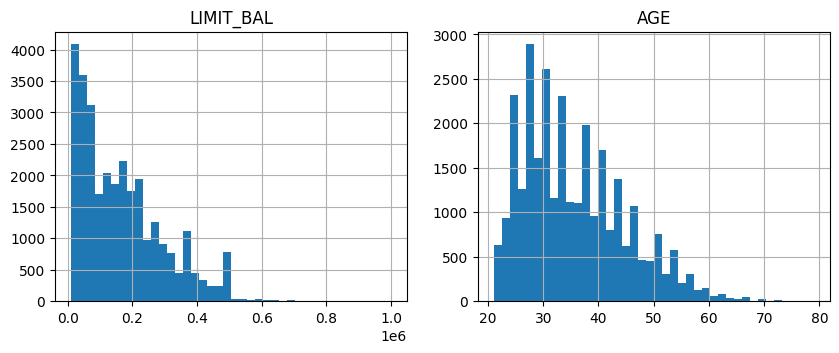

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default
count,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,3.000000e+04,30000.000000,30000.000000,30000.000000,30000.000000,3.000000e+04,30000.00000,30000.000000,30000.000000,30000.000000,30000.000000
mean,15000.500000,167484.322667,1.603733,1.853133,1.551867,35.485500,-0.016700,-0.133767,-0.166200,-0.220667,-0.266200,-0.291100,51223.330900,49179.075167,4.701315e+04,43262.948967,40311.400967,38871.760400,5663.580500,5.921163e+03,5225.68150,4826.076867,4799.387633,5215.502567,0.221200
std,8660.398374,129747.661567,0.489129,0.790349,0.521970,9.217904,1.123802,1.197186,1.196868,1.169139,1.133187,1.149988,73635.860576,71173.768783,6.934939e+04,64332.856134,60797.155770,59554.107537,16563.280354,2.304087e+04,17606.96147,15666.159744,15278.305679,17777.465775,0.415062
min,1.000000,10000.000000,1.000000,0.000000,0.000000,21.000000,-2.000000,-2.000000,-2.000000,-2.000000,-2.000000,-2.000000,-165580.000000,-69777.000000,-1.572640e+05,-170000.000000,-81334.000000,-339603.000000,0.000000,0.000000e+00,0.00000,0.000000,0.000000,0.000000,0.000000
25%,7500.750000,50000.000000,1.000000,1.000000,1.000000,28.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,3558.750000,2984.750000,2.666250e+03,2326.750000,1763.000000,1256.000000,1000.000000,8.330000e+02,390.00000,296.000000,252.500000,117.750000,0.000000
50%,15000.500000,140000.000000,2.000000,2.000000,2.000000,34.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,22381.500000,21200.000000,2.008850e+04,19052.000000,18104.500000,17071.000000,2100.000000,2.009000e+03,1800.00000,1500.000000,1500.000000,1500.000000,0.000000
75%,22500.250000,240000.000000,2.000000,2.000000,2.000000,41.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,67091.000000,64006.250000,6.016475e+04,54506.000000,50190.500000,49198.250000,5006.000000,5.000000e+03,4505.00000,4013.250000,4031.500000,4000.000000,0.000000
max,30000.000000,1000000.000000,2.000000,6.000000,3.000000,79.000000,8.000000,8.000000,8.000000,8.000000,8.000000,8.000000,964511.000000,983931.000000,1.664089e+06,891586.000000,927171.000000,961664.000000,873552.000000,1.684259e+06,896040.00000,621000.000000,426529.000000,528666.000000,1.000000


In [105]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
df["LIMIT_BAL"].hist(bins=40, ax=ax[0]); ax[0].set_title("LIMIT_BAL")
df["AGE"].hist(bins=40, ax=ax[1]); ax[1].set_title("AGE")
plt.show()
df.describe()

In [106]:
print(df["SEX"].value_counts().sort_index())
print(df["EDUCATION"].value_counts().sort_index())
print(df["MARRIAGE"].value_counts().sort_index())

PAY_COLS = ["PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]
BILL_COLS = ["BILL_AMT1", "BILL_AMT2", "BILL_AMT3", "BILL_AMT4", "BILL_AMT5", "BILL_AMT6"]

n_bad_edu = df["EDUCATION"].isin([0, 5, 6]).sum()
n_bad_mar = (df["MARRIAGE"] == 0).sum()
share_neg_bill = (df[BILL_COLS] < 0).any(axis=1).mean()
print(f"EDUCATION 0/5/6: {n_bad_edu} rows · MARRIAGE 0: {n_bad_mar} rows · {share_neg_bill:.1%} have a negative bill")
print("PAY values:", np.unique(df[PAY_COLS]))

SEX
1    11888
2    18112
Name: count, dtype: int64
EDUCATION
0       14
1    10585
2    14030
3     4917
4      123
5      280
6       51
Name: count, dtype: int64
MARRIAGE
0       54
1    13659
2    15964
3      323
Name: count, dtype: int64
EDUCATION 0/5/6: 345 rows · MARRIAGE 0: 54 rows · 6.4% have a negative bill
PAY values: [-2 -1  0  1  2  3  4  5  6  7  8]


In [107]:
# ✅ Check
assert n_bad_edu == 345 and n_bad_mar == 54
print("OK")

OK


`EDUCATION` 0, 5, 6 and `MARRIAGE` 0 are undocumented codes. Negative bills are real (overpayment) and kept. `PAY_` columns are ordered delays (−2 to 8), kept numeric. `SEX`, `EDUCATION`, `MARRIAGE` are labels, one-hot encoded.

In [108]:
print(df[TARGET].value_counts())
print(df[TARGET].value_counts(normalize=True).round(3))

default
0    23364
1     6636
Name: count, dtype: int64
default
0    0.779
1    0.221
Name: proportion, dtype: float64


22.1% default next month


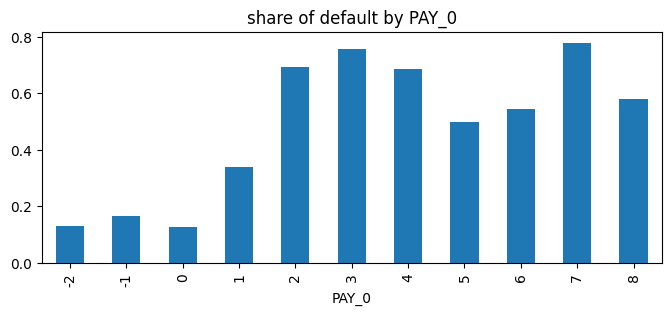

In [109]:
is_default = df[TARGET] == 1
rate_default = is_default.mean()
print(f"{rate_default:.1%} default next month")
is_default.groupby(df["PAY_0"]).mean().plot.bar(figsize=(8, 3), title="share of default by PAY_0")
plt.show()

In [110]:
# ✅ Check
assert set(df[TARGET].unique()) == {0, 1}
assert 0.2 < rate_default < 0.25
print("OK")

OK


22.1 % of clients default: "always no" gets 77.9 % accuracy, so accuracy is not the right metric. Default rate goes from about 13 % (`PAY_0` ≤ 0) to 69 % (2 months of delay).

## Part 3 · Clean

In [111]:
print(df.dtypes.value_counts())
print("missing values", df.isna().sum().sum())
print("duplicated rows", df.duplicated().sum())
print("duplicated rows without ID", df.drop(columns="ID").duplicated().sum())

int64    25
Name: count, dtype: int64
missing values 0
duplicated rows 0
duplicated rows without ID 35


In [112]:
df_clean = loader.clean(df)
print(df_clean["EDUCATION"].value_counts().sort_index())
print(df_clean["MARRIAGE"].value_counts().sort_index())
print(df_clean.shape)

EDUCATION
1    10585
2    14030
3     4917
4      468
Name: count, dtype: int64
MARRIAGE
1    13659
2    15964
3      377
Name: count, dtype: int64
(30000, 25)


In [113]:
# ✅ Check
assert set(df_clean["EDUCATION"].unique()) == {1, 2, 3, 4}
assert set(df_clean["MARRIAGE"].unique()) == {1, 2, 3}
assert len(df_clean) == len(df)
print("OK")

OK


No missing values. The 35 duplicates only appear without `ID` (different clients, same profile): kept. `EDUCATION` 0/5/6 → 4 and `MARRIAGE` 0 → 3 ("others"). No feature is known after the predicted month, so no leakage. `SEX`, `AGE`, `MARRIAGE` are sensitive attributes.

## Part 4 · Baseline

In [114]:
X_train, X_test, y_train, y_test = loader.split(df_clean)
print(X_train.shape, X_test.shape, "share of default · train:", round(y_train.mean(), 3), "| test:", round(y_test.mean(), 3))

(24000, 24) (6000, 24) share of default · train: 0.221 | test: 0.221


In [115]:
# ✅ Check
assert abs(len(X_test) / len(df_clean) - 0.2) < 0.01
assert abs(y_train.mean() - y_test.mean()) < 0.01
print("OK")

OK


In [116]:
cv = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
SCORING = {"accuracy": "accuracy", "precision": make_scorer(precision_score, zero_division=0),
           "recall": "recall", "f1": "f1", "roc_auc": "roc_auc", "average_precision": "average_precision"}

In [117]:
trainer = Trainer()
candidates = {"dummy (always no)": trainer.build_baseline(),
              "logistic regression": trainer.build_pipeline(LogisticRegression(max_iter=1000))}
rows = {}
for name, pipe in candidates.items():
    out = cross_validate(pipe, X_train, y_train, cv=cv, scoring=SCORING)
    rows[name] = {s: out[f"test_{s}"].mean() for s in SCORING}
results = pd.DataFrame(rows).T.round(3)
results

C:\Users\mciss\Documents\credit-default\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:456: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
C:\Users\mciss\Documents\credit-default\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:456: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
C:\Users\mciss\Documents\credit-default\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:456: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
C:\Users\mciss\Documents\credit-default\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:456: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
C:\Users\mciss\Documents\credit-default\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:456: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


,accuracy,precision,recall,f1,roc_auc,average_precision
dummy (always no),0.779,0.000,0.000,0.000,0.500,0.221
logistic regression,0.811,0.711,0.246,0.365,0.727,0.507


In [118]:
# ✅ Check
assert list(results.columns) == list(SCORING) and len(results) == 2
assert results.loc["logistic regression", "roc_auc"] > results.loc["dummy (always no)", "roc_auc"]
print("OK")

OK


Baseline under 5-fold stratified CV on the training set. "Always no" gets 0.779 accuracy but 0 recall: it never finds a defaulter. Logistic regression only adds 3 points of accuracy, but finds 25 % of the defaulters (recall 0.246) and ranks clients much better (ROC-AUC 0.727 vs 0.5, average precision 0.507 vs 0.221). Accuracy hides this, so we compare models on average precision and choose the threshold later.

## Part 5 · Compare three models, tuned

Logistic regression, k-NN and a linear SVM (the models of Sessions 5 and 6), each with one hyperparameter tuned by `GridSearchCV` on the training set, **same stratified 5-fold CV** as the baseline. The grids are in `config.yaml`. Models are ranked on average precision (it does not depend on the threshold, which is chosen later).

In [119]:
GRIDS = CONFIG["grids"]
models = {"logistic regression": (LogisticRegression(max_iter=1000), GRIDS["logistic_regression"]),
          "k-NN": (KNeighborsClassifier(), GRIDS["knn"]),
          "linear SVM": (LinearSVC(), GRIDS["linear_svm"])}
searches, rows = {}, {}
for name, (clf, grid) in models.items():
    search = GridSearchCV(trainer.build_pipeline(clf), grid, cv=cv, scoring=SCORING,
                          refit="average_precision").fit(X_train, y_train)
    i = search.best_index_
    searches[name] = search
    rows[name] = {s: search.cv_results_[f"mean_test_{s}"][i] for s in SCORING}
    rows[name]["best params"] = search.best_params_
tuned = pd.DataFrame(rows).T.sort_values("average_precision", ascending=False)
tuned

C:\Users\mciss\Documents\credit-default\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:456: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
C:\Users\mciss\Documents\credit-default\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:456: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
C:\Users\mciss\Documents\credit-default\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:456: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
C:\Users\mciss\Documents\credit-default\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:456: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
C:\Users\mciss\Documents\credit-default\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:456: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
C:\Users\mciss\Documents\credit-default\.venv\Lib\site-packages\sklearn\linear_model\_logi

,accuracy,precision,recall,f1,roc_auc,average_precision,best params
k-NN,0.808167,0.662432,0.271241,0.384807,0.759511,0.517446,{'clf__n_neighbors': 201}
logistic regression,0.810917,0.711309,0.24449,0.363749,0.727078,0.506864,{'clf__C': 0.1}
linear SVM,0.802875,0.724161,0.175739,0.28277,0.723964,0.504364,{'clf__C': 1}


In [120]:
{n: s.cv_results_["std_test_average_precision"][s.best_index_].round(3) for n, s in searches.items()}

{'logistic regression': np.float64(0.013),
 'k-NN': np.float64(0.014),
 'linear SVM': np.float64(0.013)}

In [121]:
# ✅ Check
assert len(tuned) == 3
assert tuned["average_precision"].max() > results.loc["dummy (always no)", "average_precision"]
print("OK")

OK


Best model on average precision: k-NN (k = 201), 0.517 ± 0.014, against logistic regression (C = 0.1), 0.507 ± 0.013, and the linear SVM, 0.504 ± 0.013 (± is the standard deviation across the 5 folds). k = 201 is inside the grid (which goes up to 301), so the search covered the best value. The gap between k-NN and logistic regression is smaller than the fold-to-fold variation, so the two are tied on our main metric. All three beat the dummy baseline (0.221).

We keep the rule we set before looking at the results, best average precision, so the final model is k-NN. It also has the best ROC-AUC (0.760) and recall. Logistic regression has the better precision at 0.5, but the threshold is moved later anyway. The linear SVM has no predict_proba, so it cannot give the probabilities the threshold needs. Because the two are tied, we use the logistic regression to interpret the features (Part 8).

## Part 6 · Threshold on out-of-fold probabilities

Each training client gets a probability from a model that did not see them (`cross_val_predict`, Session 7 Lab 2 protocol). We keep the **highest threshold whose recall is ≥ 60 %** (Session 5, 4.2): among the thresholds that catch enough defaulters, it raises the fewest false alarms. The test set is not used.

In [122]:
final_name = tuned.loc[["logistic regression", "k-NN"], "average_precision"].astype(float).idxmax()
final_model = searches[final_name].best_estimator_
MIN_RECALL = CONFIG["min_recall"]
p_oof = out_of_fold_proba(final_model, X_train, y_train, RANDOM_STATE)
threshold = choose_threshold(y_train, p_oof, MIN_RECALL)
print(f"final model: {final_name} {searches[final_name].best_params_}")
print(f"chosen threshold (out-of-fold, recall >= {MIN_RECALL:.0%}): {threshold:.2f}")

final model: k-NN {'clf__n_neighbors': 201}
chosen threshold (out-of-fold, recall >= 60%): 0.19


In [123]:
# ✅ Check
assert 0 < threshold < 0.5, "to reach 60 % recall the threshold must go below 0.5"
assert recall_score(y_train, (p_oof >= threshold).astype(int)) >= MIN_RECALL
print("OK")

OK


In [124]:
# copy these lines into config.yaml, so the CLI uses the same model and threshold
name = {"logistic regression": "logistic_regression", "k-NN": "knn"}[final_name]
params = {k.replace("clf__", ""): v for k, v in searches[final_name].best_params_.items()}
if name == "logistic_regression":
    params["max_iter"] = 1000
print(f"threshold: {threshold:.2f}")
print("model:")
print(f"  name: {name}")
print(f"  params: {params}")

threshold: 0.19
model:
  name: knn
  params: {'n_neighbors': 201}


## Part 7 · Test once

`GridSearchCV` (refit=True) already fitted the best settings on the whole training set. The test set is used **once**, with the threshold chosen above.

In [125]:
scores = evaluate(final_model, X_test, y_test, threshold=threshold)
(tn, fp), (fn, tp) = scores["confusion_matrix"]
print(f"TEST precision={scores['precision']:.3f} recall={scores['recall']:.3f} F1={scores['f1']:.3f}")
print(f"TEST average precision={scores['average_precision']:.3f} ROC-AUC={scores['roc_auc']:.3f}")
print(pd.DataFrame([[tn, fp], [fn, tp]], index=["real: no", "real: default"],
                   columns=["flagged: no", "flagged: default"]))

TEST precision=0.436 recall=0.611 F1=0.509
TEST average precision=0.516 ROC-AUC=0.753
               flagged: no  flagged: default
real: no              3625              1048
real: default          516               811


On the test set the model finds 61.1 % of the defaulters (recall: 811 of 1,327) and 43.6 % of the flagged clients really default (precision), about twice the 22 % a random flag would get. The recall is close to the 60 % we targeted out-of-fold, so the threshold generalises. The price is 1,048 safe clients flagged by mistake (22 % of the safe clients). Average precision 0.516 and ROC-AUC 0.753 are in line with the CV scores (0.517 and 0.760), so there's no sign of overfitting.

## Part 8 · Interpret


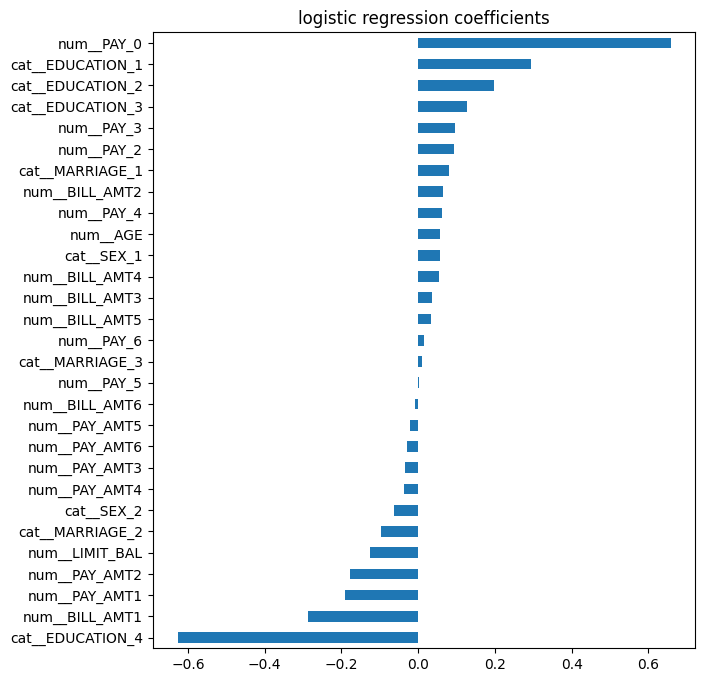

num__PAY_0          0.657887
cat__EDUCATION_4    0.627323
cat__EDUCATION_1    0.293775
num__BILL_AMT1      0.287154
cat__EDUCATION_2    0.197362
num__PAY_AMT1       0.190888
num__PAY_AMT2       0.178767
cat__EDUCATION_3    0.127807
dtype: float64

In [126]:
lr = searches["logistic regression"].best_estimator_
coefs = pd.Series(lr.named_steps["clf"].coef_[0], index=lr.named_steps["prep"].get_feature_names_out())
coefs.sort_values().plot.barh(figsize=(7, 8), title="logistic regression coefficients")
plt.show()
coefs.abs().sort_values(ascending=False).head(8)

The final model is k-NN, which has no coefficients to read. To see which features drive the risk, we look at the tuned logistic regression: it is tied with k-NN on average precision (0.507 ± 0.013 vs 0.517 ± 0.014, Part 5), and it can be read.

- **`PAY_0` is by far the strongest (+0.66):** being late on last month's payment is the clearest sign of default. `PAY_2` and `PAY_3` are also positive but much smaller, so the most recent month matters most.
- **Payments made (`PAY_AMT1`, `PAY_AMT2`) are negative:** clients who paid more in recent months are less risky.
- **`LIMIT_BAL` is negative:** clients with a higher credit limit default less, probably because the bank already gave larger limits to clients it trusted.
- **Read with care:** `BILL_AMT1` is clearly negative while `BILL_AMT2`–`5` are slightly positive. The six bill amounts are strongly correlated, so their individual signs are not reliable. `EDUCATION_4` ("others", after merging codes 0/5/6) has a large negative coefficient, but it is a very small group, so it is weak evidence. `SEX_1` (male) is slightly positive, which links to the fairness risk below.

**Two limits**
1. **Recent payment history dominates.** The model mostly reads the last months of delays; a client who has never been late yet but is about to default is hard to catch.
2. **One country, one period.** The data are Taiwanese clients from 2005: incomes, credit habits and the economy are different elsewhere and today, so the scores would need re-checking before any real use.

**Risks for real people**
A wrong "default" flag can mean a lowered limit or pressure on a client who would have paid; a missed defaulter means a debt that grows. `SEX`, `AGE` and `MARRIAGE` are sensitive attributes: using them can treat groups differently, and dropping them does not fully remove the risk, since other features can carry the same information. The tool should support a human decision, never replace it, with error rates checked per group and the data protected (financial records are personal data).